# 02 — Dataset Preparation, Split Validation & Preprocessing Readiness
**PentAI | Goats + Cattle |**

**Purpose:** Read the eligible CSV manifests from `01_data_cleaning_and_eda.ipynb`, verify that images exist and labels are valid, detect exact / perceptually similar image overlap, preserve the supplied goat train/valid/test splits, and generate leakage-aware cattle splits. Finally, inspect a small RGB, resized batch and export portable split CSVs.

**This notebook does not train a model, modify source photographs, or move/delete files.**

**Prerequisites:** Run the previous cleaning notebook successfully. Team-review and approve its exclusions. If you have not approved the decisions, outputs from this notebook must be labelled **provisional**, not training-ready.

**Expected Drive input files:** `Capstone Project/outputs/data_quality/cow_eligible_manifest.csv` and `goat_eligible_manifest.csv`.

**Execution:** Run top to bottom after mounting Google Drive; don't run later cells if an audit cell raises an exception.

**Required inputs from Notebook 01:** `cow_eligible_manifest.csv` and `goat_eligible_manifest.csv`. These must already reflect the reviewed image exclusions. Splits are not formally approved until the team reviews the outputs.

**Cattle exception:** Verified cross-label source-photo duplicates are filtered using `outputs/data_quality/cattle_verified_label_conflict_exclusions.csv`, preserving their source paths and reasons.


### Before running in Google Colab

1. Keep **`cow_eligible_manifest.csv`** and **`goat_eligible_manifest.csv`** in `MyDrive/Capstone Project/outputs/data_quality/` (from Notebook 1).
2. Upload the **approved** `goat_similarity_group_decisions.csv` to that same folder.
3. Upload `cattle_verified_label_conflict_exclusions.csv` to the same folder.
4. Keep the original `Cow data.zip` and `Goat Pox Detection.v1i.tensorflow.zip` in `MyDrive/Capstone Project/Datasets/`.
5. Choose **Runtime → Run all**. The notebook excludes the five unresolved cattle-label conflicts *without deleting source images*, then validates group-disjoint splits. A runtime validation error means further review is needed, not that it should be bypassed.

**Scope:** Goat and cattle only. **Approval:** output remains pending team sign-off. **Note:** related images may be retained together in one split; this notebook does not perform one-image-per-family deduplication.

## 1. Mount Drive and configure data locations
The previous notebook extracts ZIP files to temporary `/content/pentai_data`. Those folders disappear when Colab restarts. This notebook can extract the **same original archives** again, without changing them. Update paths in the following cell only if your Drive organization differs.

In [1]:
from google.colab import drive

drive.mount("/content/drive")

from pathlib import Path
import hashlib
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from sklearn.model_selection import GroupShuffleSplit

PROJECT_ROOT = Path("/content/drive/MyDrive/Capstone Project")
DATASETS_DIR = PROJECT_ROOT / "Datasets"
REVIEWS_DIR = PROJECT_ROOT / "outputs" / "data_quality"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "prepared"
WORK_DIR = Path("/content/pentai_data")
COW_ZIP = DATASETS_DIR / "Cow data.zip"
GOAT_ZIP = DATASETS_DIR / "Goat Pox Detection.v1i.tensorflow.zip"
COW_ROOT = WORK_DIR / "cow_data"
GOAT_ROOT = WORK_DIR / "goat_data"
SEED = 42
IMAGE_SIZE = (224, 224)  # For inspection only; model-specific sizes can change later
# No image pixels will be written to disk by this notebook.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Input manifests:", REVIEWS_DIR)
print("Output splits:", OUTPUT_DIR)

Mounted at /content/drive
Input manifests: /content/drive/MyDrive/Capstone Project/outputs/data_quality
Output splits: /content/drive/MyDrive/Capstone Project/outputs/prepared


## 2. Ensure original images are accessible
For security, archive extraction rejects absolute paths, `..` and links; archives are extracted only into `/content`. Set the working directory once to avoid creating duplicates. If ZIPs are already extracted in the current runtime, extraction will be skipped.

In [2]:
def ensure_extracted(archive: Path, destination: Path):
    if not archive.is_file():
        raise FileNotFoundError(f"Original archive missing: {archive}")
    if destination.exists() and (
        any(destination.rglob("*.png")) or any(destination.rglob("*.jpg"))
    ):
        print("Already extracted:", destination)
        return
    destination.mkdir(parents=True, exist_ok=True)
    base = destination.resolve()
    with zipfile.ZipFile(archive) as zf:
        for entry in zf.infolist():
            relative = Path(entry.filename.replace("\\", "/"))
            if relative.is_absolute() or ".." in relative.parts:
                raise ValueError(f"Unsafe ZIP member: {entry.filename}")
            if (entry.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError(f"Symlink in ZIP: {entry.filename}")
            target = (destination / relative).resolve()
            if not target.is_relative_to(base):
                raise ValueError(f"ZIP path escapes destination: {entry.filename}")
        zf.extractall(destination)
    print("Extracted:", destination)

ensure_extracted(COW_ZIP, COW_ROOT)
ensure_extracted(GOAT_ZIP, GOAT_ROOT)

Extracted: /content/pentai_data/cow_data
Extracted: /content/pentai_data/goat_data


## 3. Load eligible manifests and check their schema
This notebook expects the *eligible* CSVs from the prior notebook. These should contain **only** images with `include=True`; the original `cow_cleaning_manifest.csv` and `goat_cleaning_manifest.csv` still preserve excluded records for auditing.

Do not simply edit filenames or class labels in the CSV without documenting a cleaning decision in Notebook 01.

In [3]:
REQUIRED = {"relative_path", "class", "include"}
VALID_CLASSES = {"cattle": {"lumpy_skin", "healthy"},
                 "goat": {"goatpox", "healthy"}}

def parse_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if str(value).strip().lower() in {"true", "1", "yes"}:
        return True
    if str(value).strip().lower() in {"false", "0", "no"}:
        return False
    raise ValueError(f"Invalid include flag: {value!r}")

def load_eligible(animal: str, filename: str, root: Path):
    file = REVIEWS_DIR / filename
    if not file.is_file():
        raise FileNotFoundError(f"Run notebook 01 first. Missing: {file}")
    df = pd.read_csv(file, keep_default_na=False)
    missing = REQUIRED - set(df.columns)
    if missing:
        raise ValueError(f"{animal}: missing columns {sorted(missing)}")
    df["include"] = df["include"].map(parse_bool)
    if not df["include"].all():
        raise ValueError(f"{animal}: an eligible manifest contains excluded rows")
    if not len(df) or not df["relative_path"].is_unique:
        raise ValueError(f"{animal}: empty manifest or duplicated paths")
    if not set(df["class"]).issubset(VALID_CLASSES[animal]):
        raise ValueError(f"{animal}: unexpected classes: {sorted(set(df['class']))}")
    df["animal"] = animal
    root_abs = root.resolve()
    def locate(rel):
        p = Path(str(rel).replace("\\", "/"))
        if p.is_absolute() or ".." in p.parts:
            raise ValueError(f"Unsafe relative_path: {rel}")
        resolved = (root / p).resolve()
        if not resolved.is_relative_to(root_abs) or not resolved.is_file():
            raise FileNotFoundError(f"Missing or escaped image: {resolved}")
        return str(resolved)
    df["_abs_path"] = df["relative_path"].map(locate)  # local only; never export
    return df

cow = load_eligible("cattle", "cow_eligible_manifest.csv", COW_ROOT)
goat = load_eligible("goat", "goat_eligible_manifest.csv", GOAT_ROOT)
if "split" not in goat.columns:
    raise ValueError("The goat eligible CSV must contain its original split column")
if not set(goat["split"]).issubset({"train", "valid", "test"}):
    raise ValueError("Unexpected goat split name")
if set(goat["split"]) != {"train", "valid", "test"}:
    raise ValueError("Goat must have train, valid and test samples")
print("Cattle eligible:", len(cow), "| Goats eligible:", len(goat))
print("Cattle classes:\n", cow["class"].value_counts())
print("Goat classes / original splits:\n", pd.crosstab(goat["split"], goat["class"]))

Cattle eligible: 1016 | Goats eligible: 1004
Cattle classes:
 class
healthy       697
lumpy_skin    319
Name: count, dtype: int64
Goat classes / original splits:
 class  goatpox  healthy
split                  
test        36       63
train      280      423
valid       80      122


### Documented cattle label-conflict exclusions

Five source-photo duplicates occur under both cattle labels. Their disease class is unresolved, so we exclude them from model preparation while retaining source files and the audit CSV. This must also be recorded in the next update of Notebook 01 cleaning manifests.


In [4]:
# Cattle label-conflict exclusions (manually verified against original Cow ZIP, 2026-11-02).
# Keep the original image files and cleaning manifests unchanged for auditing.
# The exclusion CSV is placed under outputs/data_quality in Google Drive.
EXCLUSION_FILE = REVIEWS_DIR / "cattle_verified_label_conflict_exclusions.csv"
if not EXCLUSION_FILE.is_file():
    raise FileNotFoundError(f"Upload the reviewed cattle exclusion CSV to: {EXCLUSION_FILE}")
exclusions = pd.read_csv(EXCLUSION_FILE, keep_default_na=False)
required_excl = {"relative_path", "decision", "reason"}
if not required_excl.issubset(exclusions.columns):
    raise ValueError("The cattle exclusion CSV is missing required columns")
if not exclusions["relative_path"].is_unique:
    raise ValueError("Cattle exclusion CSV has duplicate relative paths")
if not exclusions["decision"].eq("exclude_pending_source_label_verification").all():
    raise ValueError("Cattle exclusion CSV contains unapproved decision strings")
missing = set(exclusions["relative_path"]) - set(cow["relative_path"])
if missing:
    raise ValueError(f"Exclusion records not in eligible manifest: {sorted(missing)}")
expected = {
    "Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Skin_288.png",
    "Lumpy Skin Images Dataset/Normal Skin/Normal_Skin_347.png",
    "Lumpy Skin Images Dataset/Lumpy Skin/Lumpy_Skin_51.png",
    "Lumpy Skin Images Dataset/Normal Skin/Normal_Skin_510.png",
    "Lumpy Skin Images Dataset/Normal Skin/Normal_Skin_5.png",
}
if set(exclusions["relative_path"]) != expected:
    raise ValueError("Reviewed exclusion records differ from the five verified conflicts")
cow = cow.loc[~cow["relative_path"].isin(expected)].copy().reset_index(drop=True)
print(f"Excluded {len(exclusions)} contradictory-label cattle images; {len(cow)} cattle images remain eligible.")
print("The raw Cow ZIP and Notebook 01 output files were not modified.")


Excluded 5 contradictory-label cattle images; 1011 cattle images remain eligible.
The raw Cow ZIP and Notebook 01 output files were not modified.


## 4. Verify full image decoding and calculate hashes
SHA-256 finds **byte-identical** files. A 64-bit difference hash (dHash) helps flag visually similar images, even if their bytes differ. Similarity is a *screening signal*, not proof that two photos depict the same animal. We use it to prevent possible leakage until reviewed.

A small dataset like this is manageable in Colab. No photos are modified.

In [5]:
def dhash(image: Image.Image, size=8) -> int:
    gray = ImageOps.grayscale(image).resize((size + 1, size), Image.Resampling.LANCZOS)
    pixels = np.asarray(gray)
    bits = pixels[:, 1:] > pixels[:, :-1]
    value = 0
    for bit in bits.flat:
        value = (value << 1) | int(bit)
    return value

def inspect_images(df: pd.DataFrame, animal: str):
    hashes, similarity_hashes, errors = [], [], []
    for path in df["_abs_path"]:
        try:
            hashes.append(hashlib.sha256(Path(path).read_bytes()).hexdigest())
            with Image.open(path) as original:
                rgb = ImageOps.exif_transpose(original).convert("RGB")
                rgb.load()  # full decode, not just header verification
                similarity_hashes.append(dhash(rgb))
        except (OSError, ValueError, UnidentifiedImageError) as exc:
            hashes.append("")
            similarity_hashes.append(-1)
            errors.append((path, str(exc)))
    if errors:
        pd.DataFrame(errors, columns=["path", "error"]).to_csv(
            OUTPUT_DIR / f"{animal}_decoding_errors.csv", index=False)
        raise ValueError(f"{animal}: {len(errors)} images failed decoding; see error report")
    out = df.copy()
    out["sha256"] = hashes
    out["_dhash"] = similarity_hashes
    return out

cow = inspect_images(cow, "cattle")
goat = inspect_images(goat, "goat")
print("Full decode passed: both datasets")

Full decode passed: both datasets


## 5. Review goat cross-split similarity, then prepare an approved group-aware split

The original Roboflow goat train/valid/test assignment is a **source split**, not automatically a leak-free evaluation split. SHA-256 catches byte-identical files; dHash flags possible visually related images. dHash is heuristic: **a flagged group is not proof of duplication**.

On the first run this cell writes `goat_similarity_group_decisions.csv` under `outputs/data_quality` and stops. Visually review each flagged group and enter `confirmed_related` (same source/related images that must stay together) or `false_positive` (all images in that group are independent). Enter your name and notes. Do not merely change all decisions to pass.

After review, the code recomputes similarity groups and forms a NEW group-aware goat split if any original cross-split groups are confirmed related. It preserves original source split in `original_split`. All groups are checked again before exporting. The untouched original archive and source annotations are retained. Review status remains pending team signoff.

**Additional safeguard:** the visual review also revealed some identical source photographs spread across *different* dHash group IDs. The reviewed version below merges those related groups before splitting; do not assume separate dHash group numbers mean independent photographs.


In [6]:
NEAR_THRESHOLD = 2

def build_similarity_groups(df, threshold=NEAR_THRESHOLD):
    # Connected components of exact matches and dHash near matches.
    vals = df["_dhash"].tolist()
    exact = df["sha256"].tolist()
    parent = list(range(len(df)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra
    for i in range(len(df)):
        for j in range(i + 1, len(df)):
            if exact[i] == exact[j] or (vals[i] ^ vals[j]).bit_count() <= threshold:
                union(i, j)
    result = df.copy()
    result["similarity_group"] = [find(i) for i in range(len(df))]
    return result

def choose_split(df, test_fraction, seed, trials=150):
    """Choose a group-disjoint split with both labels and approximate class ratio."""
    goal = df["class"].value_counts(normalize=True)
    classes = set(goal.index)
    best = None
    for t in range(trials):
        splitter = GroupShuffleSplit(n_splits=1, test_size=test_fraction,
                                     random_state=seed+t)
        a, b = next(splitter.split(df, groups=df["similarity_group"]))
        left, right = df.iloc[a].copy(), df.iloc[b].copy()
        if set(left["class"]) != classes or set(right["class"]) != classes:
            continue
        size_err = abs(len(right) / len(df) - test_fraction)
        balance_err = sum(abs(right["class"].value_counts(normalize=True).get(k, 0) - v)
                          for k, v in goal.items())
        score = 2 * size_err + balance_err
        if best is None or score < best[0]:
            best = (score, left, right)
    if best is None:
        raise RuntimeError("Cannot create class-complete group-disjoint split; review counts")
    return best[1], best[2]

goat = build_similarity_groups(goat)
goat_group_splits = goat.groupby("similarity_group")["split"].nunique()
goat_group_labels = goat.groupby("similarity_group")["class"].nunique()
flag_ids = set(goat_group_splits[goat_group_splits > 1].index) | set(
    goat_group_labels[goat_group_labels > 1].index)
flagged = goat[goat["similarity_group"].isin(flag_ids)].copy()

# A contradictory-label group must be resolved at the annotation/cleaning stage.
conflicts = set(goat_group_labels[goat_group_labels > 1].index)
if conflicts:
    flagged.drop(columns=["_abs_path", "_dhash"], errors="ignore").to_csv(
        OUTPUT_DIR / "goat_leakage_review.csv", index=False)
    raise RuntimeError(f"{len(conflicts)} similarity groups have contradictory labels. "
                       "Resolve verified labels or exclude unresolved images in Notebook 01.")

goat["original_split"] = goat["split"]
if len(flagged):
    flagged.drop(columns=["_abs_path", "_dhash"], errors="ignore").to_csv(
        OUTPUT_DIR / "goat_leakage_review.csv", index=False)
    decision_file = REVIEWS_DIR / "goat_similarity_group_decisions.csv"
    group_review = flagged.groupby("similarity_group").agg(
        image_count=("relative_path", "size"),
        class_name=("class", "first"),
        original_splits=("split", lambda x: ",".join(sorted(set(x)))),
        sample_paths=("relative_path", lambda x: " | ".join(list(x)[:5]))
    ).reset_index()
    if not decision_file.exists():
        group_review["decision"] = "pending"
        group_review["reviewer"] = ""
        group_review["review_notes"] = ""
        decision_file.parent.mkdir(parents=True, exist_ok=True)
        group_review.to_csv(decision_file, index=False)
        display(group_review.head(20))
        raise RuntimeError("Manual image-group review required. Edit decisions in: "
                           + str(decision_file))
    decisions = pd.read_csv(decision_file, keep_default_na=False)
    necessary = {"similarity_group", "decision", "reviewer", "review_notes"}
    if not necessary.issubset(decisions.columns) or not decisions["similarity_group"].is_unique:
        raise ValueError("Review CSV must have unique group IDs and decision/reviewer/notes")
    if set(decisions["similarity_group"]) != set(group_review["similarity_group"]):
        raise RuntimeError("Similarity groups changed since review; archive prior review and "
                           "regenerate decisions CSV after verifying data.")
    good = {"confirmed_related", "false_positive"}
    unfinished = decisions[~decisions["decision"].isin(good) |
                           decisions["reviewer"].str.strip().eq("") |
                           decisions["review_notes"].str.strip().eq("")]
    if len(unfinished):
        display(unfinished.head(20))
        raise RuntimeError(f"{len(unfinished)} groups remain unreviewed. "
                           f"Complete decision, reviewer and notes in {decision_file}")
    false_groups = set(decisions.loc[decisions["decision"].eq("false_positive"),
                                     "similarity_group"])
    # A false-positive group is split into independent samples ONLY after review.
    # Exact SHA-256 duplicate images cannot be cleared as independent.
    false_rows = goat[goat["similarity_group"].isin(false_groups)]
    if false_rows["sha256"].duplicated().any():
        raise RuntimeError("An approved false-positive group contains exact duplicate files; "
                           "mark it confirmed_related and re-review.")
    goat["similarity_group"] = goat["similarity_group"].astype(str)
    false_mask = goat["similarity_group"].isin({str(x) for x in false_groups})
    goat.loc[false_mask, "similarity_group"] = [
        "independent_" + str(i) for i in goat.index[false_mask]]
    # Visually verified source-image families can span separate dHash groups.
    # These links were identified by comparing actual images in the review sheets.
    # Treat each family as ONE group to prevent cross-family leakage.
    VISUAL_SOURCE_FAMILIES = [
        (8, 40, 141), (70, 751), (79, 201), (80, 779),
        (119, 238), (128, 767), (133, 150),
        (166, 182, 194), (223, 261),
    ]
    approved_related = set(decisions.loc[
        decisions["decision"].eq("confirmed_related"), "similarity_group"
    ].astype(str))
    family_merges = {}
    for family in VISUAL_SOURCE_FAMILIES:
        present = [str(gid) for gid in family if str(gid) in approved_related]
        if len(present) > 1:
            canonical = "visual_family_" + str(min(int(g) for g in present))
            family_merges.update({group_id: canonical for group_id in present})
    goat["similarity_group"] = goat["similarity_group"].replace(family_merges)
    if family_merges:
        print(f"Merged {len(family_merges)} dHash groups into "
              f"{len(set(family_merges.values()))} visually linked source-image families.")

    needs_resplit = bool(set(flag_ids) - false_groups)
    if needs_resplit:
        goat_train, goat_holdout = choose_split(goat, 0.30, SEED)
        goat_valid, goat_test = choose_split(goat_holdout, 0.50, SEED+300)
        for part, split_name in ((goat_train, "train"), (goat_valid, "valid"),
                                 (goat_test, "test")):
            part["split"] = split_name
        goat = pd.concat([goat_train, goat_valid, goat_test], ignore_index=True)
        print("NEW goat group-aware splits generated after documented review.")
    else:
        print("Review accepted all flagged groups as independent; original split retained.")
else:
    print("Original goat split passed similarity review.")
print("Goat split distribution:\n", pd.crosstab(goat["split"], goat["class"]))


Merged 20 dHash groups into 9 visually linked source-image families.
NEW goat group-aware splits generated after documented review.
Goat split distribution:
 class  goatpox  healthy
split                  
test        60       91
train      277      426
valid       59       91


## 6. Group cattle images before splitting
Cattle comes without original split information. Grouping by potential near-duplicates **before** splitting helps prevent related images landing in train and test. If a similarity group carries both `healthy` and `lumpy_skin`, the notebook stops: its labels must be reviewed first.

We aim for a **70 / 15 / 15** ratio using group-aware random sampling. Exact percentages are not guaranteed because entire similarity groups must stay intact.

In [7]:
cow = build_similarity_groups(cow)
conflicts = cow.groupby("similarity_group")["class"].nunique()
problem_groups = set(conflicts[conflicts > 1].index)
if problem_groups:
    review = cow[cow["similarity_group"].isin(problem_groups)]
    review.drop(columns=["_abs_path", "_dhash"], errors="ignore").to_csv(
        OUTPUT_DIR / "cattle_similarity_conflicts.csv", index=False)
    display(review[["relative_path", "class", "similarity_group"]].head(30))
    raise RuntimeError("Cattle potential visually similar images have contradictory labels; review before splitting")

# Use the group-aware split helper defined in section 5.
cow_train, cow_holdout = choose_split(cow, test_fraction=0.30, seed=SEED)
cow_valid, cow_test = choose_split(cow_holdout, test_fraction=0.50, seed=SEED+200)
cow_train["split"] = "train"
cow_valid["split"] = "valid"
cow_test["split"] = "test"
cow_final = pd.concat([cow_train, cow_valid, cow_test], ignore_index=True)
goat_final = goat.copy()  # Reviewed goat split (original or approved group-aware).
print("Cattle split counts:\n", pd.crosstab(cow_final["split"], cow_final["class"]))
print("Goat split counts:\n", pd.crosstab(goat_final["split"], goat_final["class"]))

Cattle split counts:
 class  healthy  lumpy_skin
split                     
test       104          48
train      486         222
valid      104          47
Goat split counts:
 class  goatpox  healthy
split                  
test        60       91
train      277      426
valid       59       91


**Goat approval reminder:** `goat_similarity_group_decisions.csv` is a manual audit record. A dHash threshold of 2 is only a screening heuristic; inspect actual images and original source identifiers before approval. Keep original source splits in the cleaning manifest for traceability.

## 7. Final split validation and approval gate
Checks class coverage, missing paths, duplicate entries, exact leakage and near-similar group leakage. **No output is labelled approved automatically:** team sign-off and the source cleaning decision record remain necessary.

In [8]:
def assert_valid_splits(df, animal):
    expected = {"train", "valid", "test"}
    assert set(df["split"]) == expected, f"{animal}: missing split"
    assert df["relative_path"].is_unique, f"{animal}: duplicate input paths"
    assert df["_abs_path"].map(lambda p: Path(p).is_file()).all()
    for part in expected:
        subset = df[df["split"] == part]
        assert len(subset), f"{animal}: empty {part}"
        assert set(subset["class"]) == VALID_CLASSES[animal], (
            f"{animal}: not all classes occur in {part}")
    assert (df.groupby("sha256")["split"].nunique() <= 1).all(), (
        f"{animal}: exact leakage")
    assert (df.groupby("similarity_group")["split"].nunique() <= 1).all(), (
        f"{animal}: suspected near-duplicate group leakage")
    print(animal, "checks passed;", len(df), "eligible images")

assert_valid_splits(cow_final, "cattle")
assert_valid_splits(goat_final, "goat")

cattle checks passed; 1011 eligible images
goat checks passed; 1004 eligible images


## 8. Inspect preprocessing on a small sample (without changing originals)
Image orientation is corrected where EXIF metadata exists, then images are converted to RGB, resized to a sample target, and scaled to `float32` in `[0, 1]`. **This is a smoke test only.** Later model training must use the preprocessing required by its specific architecture (e.g. some pretrained models require a dedicated `preprocess_input`). Augmentation, if used, must be applied only to the training split.

cattle: batch shape=(4, 224, 224, 3), range=(0.000, 1.000)


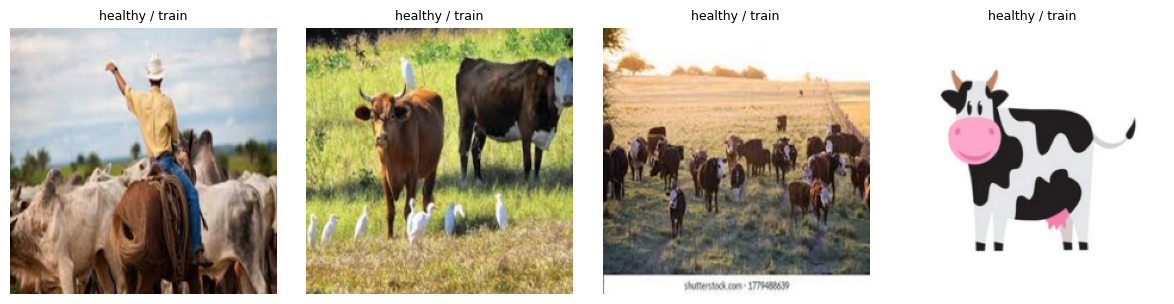

goat: batch shape=(4, 224, 224, 3), range=(0.000, 1.000)


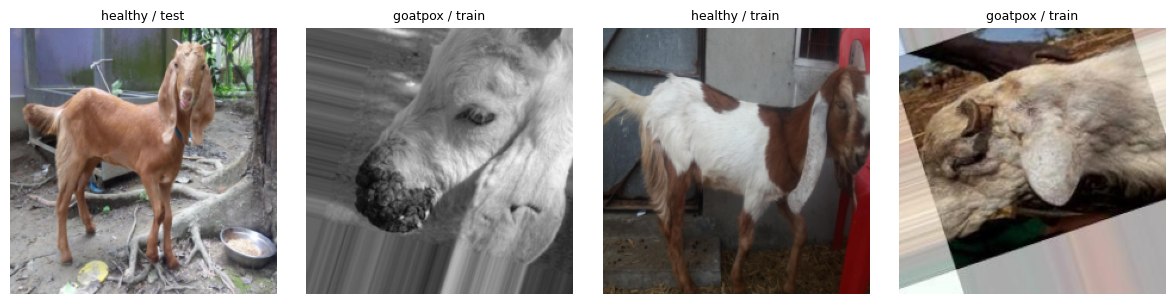

In [9]:
def load_rgb_batch(df, sample_size=4, size=IMAGE_SIZE):
    subset = df.sample(min(sample_size, len(df)), random_state=SEED)
    images = []
    for path in subset["_abs_path"]:
        with Image.open(path) as original:
            image = ImageOps.exif_transpose(original).convert("RGB")
            image = image.resize(size, Image.Resampling.BILINEAR)
            images.append(np.asarray(image, dtype=np.float32) / 255.0)
    return np.stack(images), subset

for animal, df in [("cattle", cow_final), ("goat", goat_final)]:
    arr, rows = load_rgb_batch(df)
    assert arr.shape[-1] == 3 and arr.dtype == np.float32
    assert 0 <= float(arr.min()) <= float(arr.max()) <= 1
    print(f"{animal}: batch shape={arr.shape}, range=({arr.min():.3f}, {arr.max():.3f})")
    fig, axes = plt.subplots(1, len(arr), figsize=(12, 3), squeeze=False)
    for ax, im, (_, r) in zip(axes[0], arr, rows.iterrows()):
        ax.imshow(im)
        ax.set_title(f"{r['class']} / {r['split']}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 9. Export six portable split manifests and a summary
Export only relative paths, class labels and split names. **Do not store absolute `/content` paths in GitHub.** Keep the image ZIP archives in Drive and include only the small CSV split manifests in Git once reviewed.

*Important:* CSVs are **provisional until a human explicitly signs off**. The notebook prints a summary, but cannot independently validate veterinary diagnoses.

In [10]:
import json
EXPORT_COLS = ["relative_path", "class", "split", "animal", "sha256", "similarity_group"]
summary = {"seed": SEED, "near_duplicate_threshold": NEAR_THRESHOLD,
           "split_counts": {}, "approval_status": "PENDING_TEAM_SIGNOFF",
           "goat_review_decisions": str(REVIEWS_DIR / "goat_similarity_group_decisions.csv")}
for animal, df in (("cattle", cow_final), ("goat", goat_final)):
    summary["split_counts"][animal] = pd.crosstab(
        df["split"], df["class"]).to_dict()
    for split in ("train", "valid", "test"):
        columns = EXPORT_COLS + (["original_split"] if animal == "goat" else [])
        export = df.loc[df["split"] == split, columns].copy()
        export.to_csv(OUTPUT_DIR / f"{animal}_{split}.csv", index=False)
with open(OUTPUT_DIR / "split_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("Saved six split CSV files to:", OUTPUT_DIR)
print("Saved split_summary.json (PENDING_TEAM_SIGNOFF)")

Saved six split CSV files to: /content/drive/MyDrive/Capstone Project/outputs/prepared
Saved split_summary.json (PENDING_TEAM_SIGNOFF)


## 10. How to finish this stage

1. Verify output counts and class distributions, and inspect sample images above.
2. Review any flagged potential near-duplicates using the CSV generated in `outputs/prepared/`; if the notebook stops, fix the underlying eligible manifest in Notebook 01 rather than bypassing the check.
3. Confirm cattle and goat source-label semantics with the team. Obtain formal approval of cleaning decisions and partitioning methodology.
4. Copy the **six approved CSV files** to GitHub under `data/splits/`. Add a short summary of the methodology and results to `docs/dataset_inventory.md`. Do not commit raw image ZIP files or temporary extraction paths.
5. Your next notebook can be `03_baseline_model_training.ipynb`: **separate goat and cattle baseline models** with train-only augmentation, validation tuning and held-out test evaluation.

### Key safeguards
- Goat train/valid/test assignments come from the original dataset and are **not** reshuffled.
- Cattle partitions are created **only after** duplicate grouping and label-conflict checks.
- Near-duplicate detection can miss transformed images and can falsely flag similar-looking backgrounds. Manual review is still necessary.
- Original archives are never modified. Reports and manifests select which images downstream pipelines may read.